# Cahn–Hilliard

$$
f_t = \Delta\!\left(f^3 - f\right) - \varepsilon^2\,\Delta^2 f = -\Delta f + \Delta f^3 - \varepsilon^2\,\Delta^2 f, \qquad \varepsilon = 0.2
$$

## 1. Setup

In [1]:
import numpy as np

import nb_helpers as nb
from equivariant_pde_find.simulations import cahn_hilliard

EQ = "ch"
NOISE = 0.02

# ── Best configurations from the hyperparameter sweep ───────────────
#
#   "eq"  = best of  multigraph / mod_multigraph
#   "neq" = best of  wsindy / polyjet
#
# ────────────────────────────────────────────────────────────────────
BEST = {
    (0.00, "eq"): dict(
        library="mod_multigraph", method="weak_direct",
        algorithm="stridge", backend="spectral", m=12, lam=1e-6,
        d_tol=1.0,
    ),
    (0.00, "neq"): dict(
        library="wsindy", method="weak_direct", algorithm="rfe",
        backend="spectral", m=12, lam=0.0,
    ),
    (0.02, "eq"): dict(
        library="mod_multigraph", method="weak_ibp", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=10.0,
    ),
    (0.02, "neq"): dict(
        library="wsindy", method="weak_direct", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=10.0,
    ),
}

## 2. Generate the data

In [2]:
SIM = dict(N=128, L=8 * np.pi, T_end=30.0, eps=0.2, dt=0.005,
           save_every=30, seed=42)

clean, times = cahn_hilliard(**SIM, obs_noise=0.0)
noisy, _ = cahn_hilliard(**SIM, obs_noise=NOISE)

print(f'{len(clean)} snapshots over t ∈ [{times[0]:.2f}, {times[-1]:.2f}]'
      f' on a {clean.shape[1]}×{clean.shape[2]} grid')
print(f'f ∈ [{clean.min():.3f}, {clean.max():.3f}]')
nb.check_matches_dataset(clean, EQ, 'clean')
nb.check_matches_dataset(noisy, EQ, 'noise2pct')

201 snapshots over t ∈ [0.01, 30.00] on a 128×128 grid
f ∈ [-1.042, 1.025]
  vs data/ch_clean.npz: max|Δ| = 0.00e+00  → identical


  vs data/ch_noise2pct.npz: max|Δ| = 0.00e+00  → identical


0.0

## 3. The motion

written: results/figures/ch_motion.pdf
written: results/figures/ch_motion.png


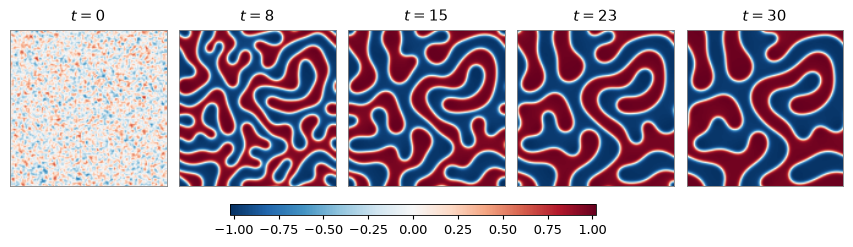

In [3]:
fig, paths = nb.plot_motion(
    clean, times, SIM['L'], n_frames=5,
    cmap='RdBu_r', symmetric=True,
    time_fmt='.0f',
    save_as=f'{EQ}_motion',
)
for p in paths:
    print('written:', p.split('/code/')[-1])

## 4. Design matrices

In [4]:
Lx = Ly = SIM['L']

data = {
    0.00: nb.regression_data(clean, times, EQ),
    NOISE: nb.regression_data(noisy, times, EQ),
}
print(f'{len(data[0.00][0])} interior snapshots')

ev = nb.JetEvaluator(clean, times, Lx, Ly, EQ)
ev.summary()

designs, fits = {}, {}
for key, cfg in BEST.items():
    f_snaps, ft_snaps, idx_sets, _ = data[key[0]]
    Theta, Ft, desc = nb.build_design(
        f_snaps, ft_snaps, idx_sets, Lx, Ly, cfg)
    designs[key] = (Theta, Ft, desc)
    fits[key] = nb.run_fit(Theta, Ft, cfg)
    print(f'{key[0] * 100:>3.0f}%  {key[1]:<4} {cfg["library"]:<15} '
          f'Theta {str(Theta.shape):<13} cond {np.linalg.cond(Theta):.2e}')

199 interior snapshots


Evaluation space: 119 jet monomials, 3,260,416 rows, 9 true active terms


  0%  eq   mod_multigraph  Theta (39800, 20)   cond 6.50e+03


  0%  neq  wsindy          Theta (39800, 46)   cond 2.77e+02


  2%  eq   mod_multigraph  Theta (39800, 20)   cond 6.91e+03


  2%  neq  wsindy          Theta (39800, 46)   cond 2.76e+02


## 5. Recovery with clean data

In [5]:
print('Ground truth:  f_t = −Δf + Δf³ − 0.04·Δ²f')
print()
for group in ('eq', 'neq'):
    key = (0.00, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = −Δf + Δf³ − 0.04·Δ²f



── Modified multigraph ──
   Modified multigraph · weak (direct) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=1
   f_t = (-0.98808)Δf + (+0.98946)Δf³ + (-0.03954)Δ²f
   3 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.01362   max|Δc| = 0.0632



── WSINDy ──
   WSINDy · weak (direct) · RFE · spectral derivatives · m=12, p=6 · λ=0
   f_t = (-0.98845)f_{yy} + (-0.98975)f_{xx} + (-0.03955)f_{yyyy} + (-0.07914)f_{xxyy} + (-0.03963)f_{xxxx} + (+0.98832)(f³)_{yy} + (+0.98952)(f³)_{xx}
   7 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.01615   max|Δc| = 0.0701



In [6]:
for group in ('eq', 'neq'):
    key = (0.00, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Modified multigraph:
term        recovered        true       error
─────────────────────────────────────────────
f·f_x²        5.93679     6.00000   -6.32e-02
f·f_y²        5.93679     6.00000   -6.32e-02
f²·f_xx       2.96839     3.00000   -3.16e-02
f²·f_yy       2.96839     3.00000   -3.16e-02
f_xx         -0.98808    -1.00000    1.19e-02
f_yy         -0.98808    -1.00000    1.19e-02
f_xxyy       -0.07908    -0.08000    9.15e-04
f_xxxx       -0.03954    -0.04000    4.58e-04
f_yyyy       -0.03954    -0.04000    4.58e-04

WSINDy:
term        recovered        true       error
─────────────────────────────────────────────
f·f_x²        5.93715     6.00000   -6.29e-02
f·f_y²        5.92989     6.00000   -7.01e-02
f²·f_xx       2.96857     3.00000   -3.14e-02
f²·f_yy       2.96495     3.00000   -3.51e-02
f_xx         -0.98975    -1.00000    1.03e-02
f_yy         -0.98845    -1.00000    1.15e-02
f_xxyy       -0.07914    -0.08000    8.62e-04
f_xxxx       -0.03963    -0.04000    3.75e-04
f_yy

## 6. Recovery at 2 % noise

In [7]:
print('Ground truth:  f_t = −Δf + Δf³ − 0.04·Δ²f')
print()
for group in ('eq', 'neq'):
    key = (NOISE, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = −Δf + Δf³ − 0.04·Δ²f



── Modified multigraph ──
   Modified multigraph · weak (IBP) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=10
   f_t = (-0.97123)Δf + (+0.96997)Δf³ + (-0.03885)Δ²f
   3 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.03611   max|Δc| = 0.18



── WSINDy ──
   WSINDy · weak (direct) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=10
   f_t = (-0.97289)f_{yy} + (-0.96922)f_{xx} + (-0.03886)f_{yyyy} + (-0.07762)f_{xxyy} + (-0.03880)f_{xxxx} + (+0.97183)(f³)_{yy} + (+0.96811)(f³)_{xx}
   7 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.03443   max|Δc| = 0.191



In [8]:
for group in ('eq', 'neq'):
    key = (NOISE, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Modified multigraph:
term        recovered        true       error
─────────────────────────────────────────────
f·f_x²        5.81982     6.00000   -1.80e-01
f·f_y²        5.81982     6.00000   -1.80e-01
f²·f_xx       2.90991     3.00000   -9.01e-02
f²·f_yy       2.90991     3.00000   -9.01e-02
f_xx         -0.97123    -1.00000    2.88e-02
f_yy         -0.97123    -1.00000    2.88e-02
f_xxyy       -0.07770    -0.08000    2.30e-03
f_xxxx       -0.03885    -0.04000    1.15e-03
f_yyyy       -0.03885    -0.04000    1.15e-03

WSINDy:
term        recovered        true       error
─────────────────────────────────────────────
f·f_x²        5.80865     6.00000   -1.91e-01
f·f_y²        5.83098     6.00000   -1.69e-01
f²·f_xx       2.90432     3.00000   -9.57e-02
f²·f_yy       2.91549     3.00000   -8.45e-02
f_xx         -0.96922    -1.00000    3.08e-02
f_yy         -0.97289    -1.00000    2.71e-02
f_xxyy       -0.07762    -0.08000    2.38e-03
f_xxxx       -0.03880    -0.04000    1.20e-03
f_yy